# 🩺 CodeAlpha Task 4 — Exploratory Data Analysis (EDA)
## Multi-Disease Prediction Using Machine Learning
**Author:** Antigravity (ML Engineer & Technical Mentor)  
**Dataset:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2024  
**Source:** [CDC BRFSS 2024 Documentation](https://www.cdc.gov/brfss/annual_data/annual_2024.html)  

---

### Project Overview
The objective of this project is to build an interpretable, robust multi-disease risk prediction system. Rather than treating multi-disease classification as a single high-dimensional combination problem, our system trains separate binary classification models for each verified chronic disease, using an identical set of patient demographic, behavioral, and general health risk factors.

In this notebook, we systematically explore:
1. **Dataset Overview and Dimensions**
2. **Data Types and Structure**
3. **Missing-Value Analysis and Special CDC Survey Codes**
4. **Duplicate Record Inspection**
5. **Chronic Disease Prevalences (Target Variables)**
6. **Numerical Feature Distributions (Age, BMI, Days of Poor Health)**
7. **Categorical and Behavioral Risk Factors (Smoking, Physical Activity, Alcohol, Healthcare Checkup)**
8. **Correlation Analysis Between Lifestyle Indicators and Disease Outcomes**
9. **Key Clinical and Methodological Conclusions**


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling configuration
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Dataset Loading and Dimensions

We load the clean processed BRFSS 2024 dataset (`brfss_cleaned.parquet`), which contains all verified survey records with valid demographic, lifestyle, and disease target variables.


In [2]:
data_path = os.path.join("..", "data", "processed", "brfss_cleaned.parquet")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed", "brfss_cleaned.parquet")

df = pd.read_parquet(data_path)
print(f"Total Rows (Survey Respondents): {df.shape[0]:,}")
print(f"Total Columns (Features + Targets): {df.shape[1]}")
df.head()


Total Rows (Survey Respondents): 444,259
Total Columns (Features + Targets): 23


,general_health,physical_health_days,mental_health_days,diff_walk,exercise_any,smoker_status,ecig_user,heavy_drinker,checkup_interval,bmi,...,income_level,race_ethnicity,healthcare_coverage,target_diabetes,target_heart_disease,target_stroke,target_asthma,target_copd,target_kidney_disease,target_arthritis
0,3.0,2.0,0.0,0.0,1.0,4.0,1.0,0.0,1.0,22.49,...,NaN,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,1.0,3.0,1.0,0.0,1.0,25.83,...,7.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,2.0,30.0,0.0,0.0,1.0,1.0,1.0,0.0,4.0,22.53,...,NaN,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0,4.0,1.0,0.0,1.0,25.09,...,4.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,3.0,0.0,0.0,1.0,0.0,4.0,1.0,0.0,1.0,19.77,...,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


---
## 2. Feature Schema and Data Types

The dataset comprises **16 input risk factor features** and **7 chronic disease target indicators**. All variables are standardized to numerical and encoded representations suitable for machine learning pipelines.


In [3]:
feature_cols = [
    'general_health', 'physical_health_days', 'mental_health_days',
    'diff_walk', 'exercise_any', 'smoker_status', 'ecig_user',
    'heavy_drinker', 'checkup_interval', 'bmi', 'age', 'sex',
    'education_level', 'income_level', 'race_ethnicity', 'healthcare_coverage'
]

target_cols = [
    'target_diabetes', 'target_heart_disease', 'target_stroke',
    'target_asthma', 'target_copd', 'target_kidney_disease', 'target_arthritis'
]

print("=== Predictor Features (X) ===")
print(df[feature_cols].dtypes)
print("\n=== Target Variables (y) ===")
print(df[target_cols].dtypes)


=== Predictor Features (X) ===
general_health          float64
physical_health_days    float64
mental_health_days      float64
diff_walk               float64
exercise_any            float64
smoker_status           float64
ecig_user               float64
heavy_drinker           float64
checkup_interval        float64
bmi                     float64
age                     float64
sex                     float64
education_level         float64
income_level            float64
race_ethnicity          float64
healthcare_coverage     float64
dtype: object

=== Target Variables (y) ===
target_diabetes          float64
target_heart_disease     float64
target_stroke            float64
target_asthma            float64
target_copd              float64
target_kidney_disease    float64
target_arthritis         float64
dtype: object


---
## 3. Missing-Value Analysis and CDC Special Codes

### The Code 88 Survey Convention
In CDC surveys, special numeric codes are used:
- **Code 88 in PHYSHLTH and MENTHLTH:** Represents **'None' (0 days)** of illness. Treating 88 as a numeric measurement would distort healthy respondents as being sick for 88 days. During preprocessing, 88 is properly remapped to 0.0.
- **Codes 7, 77, 99:** Represent 'Don't know' or 'Refused', which are mapped to NaN.

Let us verify the missingness across all features in our cleaned dataset:


In [4]:
missing_df = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing Percentage (%)': (df.isna().sum() / len(df)) * 100
})
missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)


,Missing Count,Missing Percentage (%)
income_level,82802,18.638227
heavy_drinker,44833,10.091636
bmi,41390,9.316637
ecig_user,31435,7.075827
smoker_status,30670,6.903631
diff_walk,19478,4.384379
healthcare_coverage,17333,3.901553
physical_health_days,9969,2.243961
race_ethnicity,8415,1.894165
mental_health_days,7231,1.627654


---
## 4. Duplicate Record Analysis

We verify whether identical survey profiles exist in the feature set. Because our feature space consists of 16 demographic and behavioral dimensions across 444,000 respondents, duplicate combinations are expected by the pigeonhole principle, representing individuals with identical demographic and lifestyle profiles.


In [5]:
dup_count = df.duplicated(subset=feature_cols).sum()
print(f"Number of respondents sharing identical risk factor profiles: {dup_count:,} ({dup_count/len(df)*100:.2f}%)")
print("Notice: These represent distinct surveyed individuals who share identical survey responses across demographic and behavioral bins.")


Number of respondents sharing identical risk factor profiles: 6,210 (1.40%)
Notice: These represent distinct surveyed individuals who share identical survey responses across demographic and behavioral bins.


---
## 5. Chronic Disease Prevalence Analysis

In public health machine learning, understanding class distribution is paramount. Highly imbalanced conditions (such as Stroke at 4.4%) require class-weight adjustments and cannot be evaluated on raw accuracy alone.


In [6]:
disease_labels = [
    'Diabetes', 'Heart Disease (CHD/MI)', 'Stroke',
    'Asthma', 'COPD', 'Kidney Disease', 'Arthritis'
]

prev_data = []
for t, label in zip(target_cols, disease_labels):
    pos_count = int(df[t].sum())
    total_count = len(df)
    prev_pct = (pos_count / total_count) * 100
    prev_data.append({
        'Disease Target': label,
        'Positive Cases': pos_count,
        'Negative Cases': total_count - pos_count,
        'Prevalence (%)': prev_pct
    })

prev_df = pd.DataFrame(prev_data).sort_values(by='Prevalence (%)', ascending=True)
prev_df


,Disease Target,Positive Cases,Negative Cases,Prevalence (%)
2,Stroke,19572,424687,4.405538
5,Kidney Disease,22758,421501,5.122687
4,COPD,35005,409254,7.879413
1,Heart Disease (CHD/MI),41026,403233,9.234703
0,Diabetes,63139,381120,14.212205
3,Asthma,69454,374805,15.633673
6,Arthritis,153036,291223,34.447473


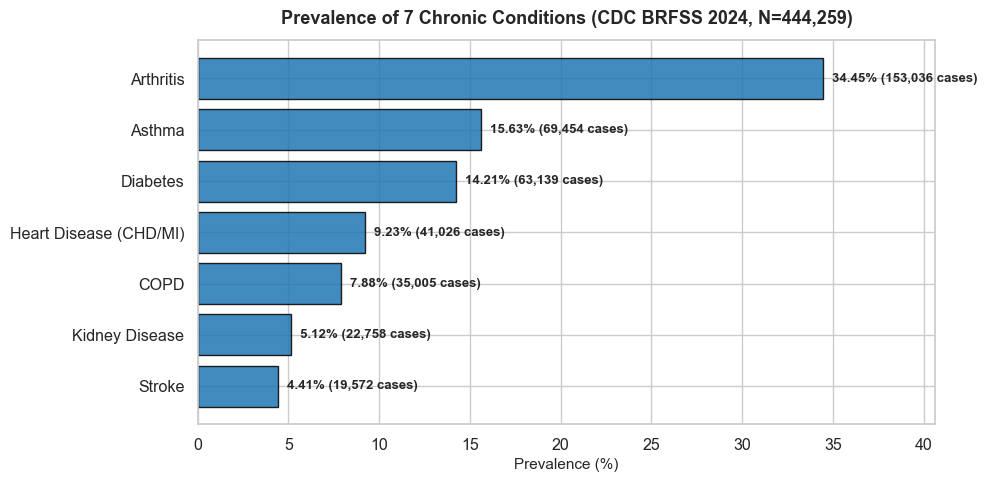

In [7]:
# Horizontal Bar Chart of Disease Prevalences
plt.figure(figsize=(10, 5))
bars = plt.barh(prev_df['Disease Target'], prev_df['Prevalence (%)'], color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title('Prevalence of 7 Chronic Conditions (CDC BRFSS 2024, N=444,259)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Prevalence (%)', fontsize=11)
plt.xlim(0, max(prev_df['Prevalence (%)']) * 1.18)

for bar, pos, prev in zip(bars, prev_df['Positive Cases'], prev_df['Prevalence (%)']):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{prev:.2f}% ({pos:,} cases)", va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 6. Numerical Feature Distributions: Age, BMI, and Health Days

We examine key continuous physiological and health indicators:
1. **Age:** Range 18 to 80 years.
2. **Body Mass Index (BMI):** Normal weight (18.5-24.9), Overweight (25-29.9), Obese (>= 30).
3. **Physical and Mental Health Days:** Number of days in the past 30 days where health was impaired.


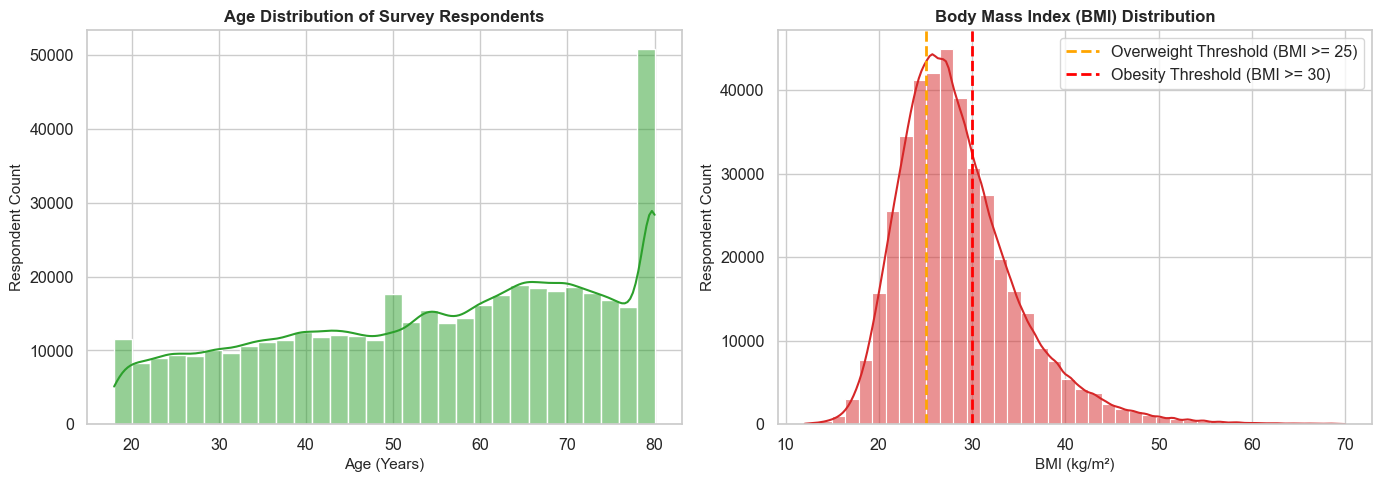

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age Distribution
sns.histplot(df['age'].dropna(), bins=30, kde=True, ax=axes[0], color='#2ca02c')
axes[0].set_title('Age Distribution of Survey Respondents', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)', fontsize=11)
axes[0].set_ylabel('Respondent Count', fontsize=11)

# BMI Distribution
sns.histplot(df['bmi'].dropna(), bins=40, kde=True, ax=axes[1], color='#d62728')
axes[1].axvline(25, color='orange', linestyle='--', lw=2, label='Overweight Threshold (BMI >= 25)')
axes[1].axvline(30, color='red', linestyle='--', lw=2, label='Obesity Threshold (BMI >= 30)')
axes[1].set_title('Body Mass Index (BMI) Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('BMI (kg/m²)', fontsize=11)
axes[1].set_ylabel('Respondent Count', fontsize=11)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


---
## 7. Behavioral and Functional Risk Factors

We analyze four critical lifestyle and functional health variables:
- **General Health Rating:** 1 (Excellent) to 5 (Poor)
- **Smoking Status:** Everyday, Somedays, Former, Never
- **Physical Activity:** Active vs Inactive in the past month
- **Difficulty Walking:** Serious difficulty walking or climbing stairs (Mobility impairment)


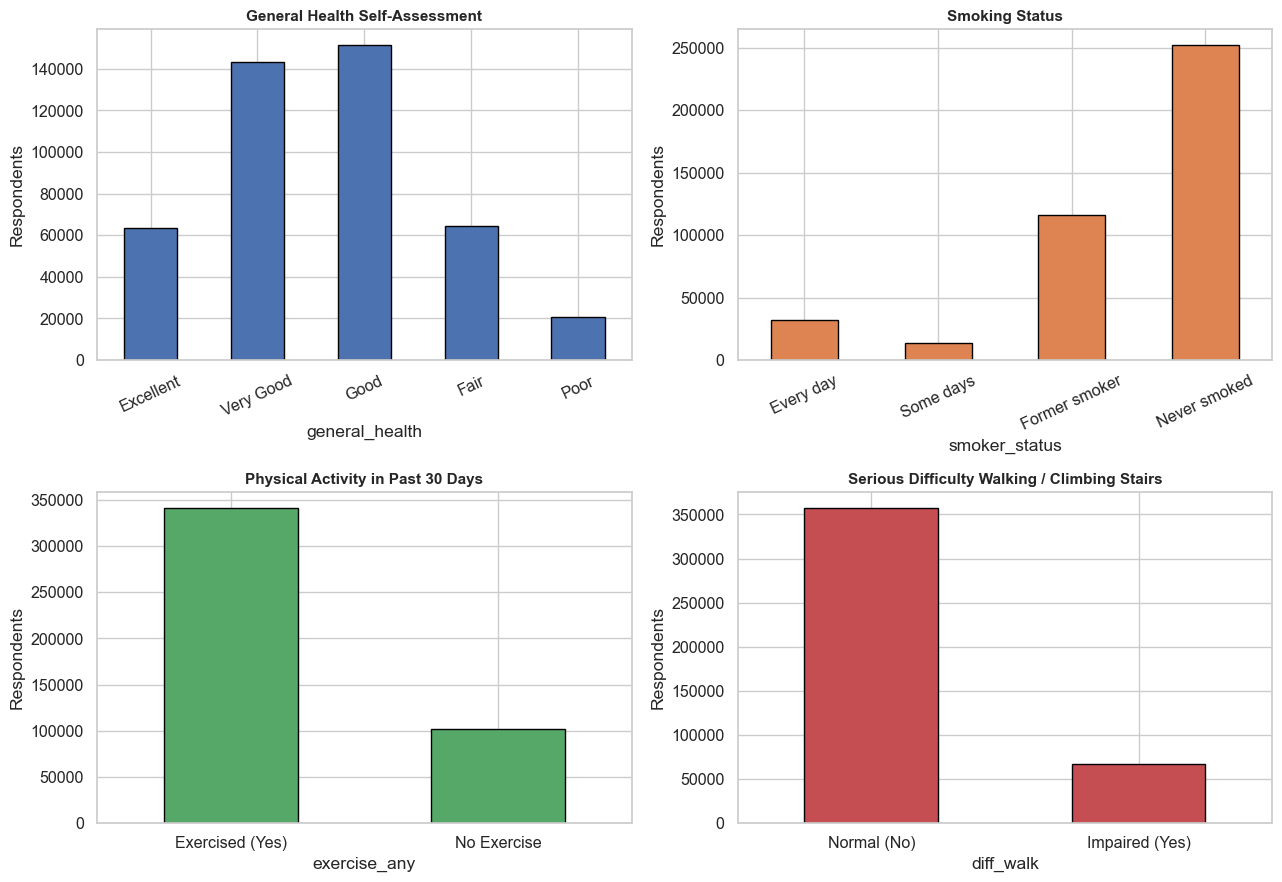

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# General Health
gh_names = {1.0: 'Excellent', 2.0: 'Very Good', 3.0: 'Good', 4.0: 'Fair', 5.0: 'Poor'}
df['general_health'].map(gh_names).value_counts()[['Excellent', 'Very Good', 'Good', 'Fair', 'Poor']].plot(
    kind='bar', ax=axes[0, 0], color='#4c72b0', edgecolor='black'
)
axes[0, 0].set_title('General Health Self-Assessment', fontweight='bold', fontsize=11)
axes[0, 0].set_ylabel('Respondents')
axes[0, 0].tick_params(axis='x', rotation=25)

# Smoking Status
smk_names = {1.0: 'Every day', 2.0: 'Some days', 3.0: 'Former smoker', 4.0: 'Never smoked'}
df['smoker_status'].map(smk_names).value_counts()[['Every day', 'Some days', 'Former smoker', 'Never smoked']].plot(
    kind='bar', ax=axes[0, 1], color='#dd8452', edgecolor='black'
)
axes[0, 1].set_title('Smoking Status', fontweight='bold', fontsize=11)
axes[0, 1].set_ylabel('Respondents')
axes[0, 1].tick_params(axis='x', rotation=25)

# Physical Activity
ex_names = {1.0: 'Exercised (Yes)', 0.0: 'No Exercise'}
df['exercise_any'].map(ex_names).value_counts().plot(
    kind='bar', ax=axes[1, 0], color='#55a868', edgecolor='black'
)
axes[1, 0].set_title('Physical Activity in Past 30 Days', fontweight='bold', fontsize=11)
axes[1, 0].set_ylabel('Respondents')
axes[1, 0].tick_params(axis='x', rotation=0)

# Difficulty Walking
walk_names = {1.0: 'Impaired (Yes)', 0.0: 'Normal (No)'}
df['diff_walk'].map(walk_names).value_counts().plot(
    kind='bar', ax=axes[1, 1], color='#c44e52', edgecolor='black'
)
axes[1, 1].set_title('Serious Difficulty Walking / Climbing Stairs', fontweight='bold', fontsize=11)
axes[1, 1].set_ylabel('Respondents')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


---
## 8. Correlation Analysis: Risk Factors vs Disease Outcomes

We construct a correlation matrix examining pairwise associations between key risk factors (General Health, Poor Physical Health Days, BMI, Age, Walking Impairment, Exercise) and the 7 chronic conditions.


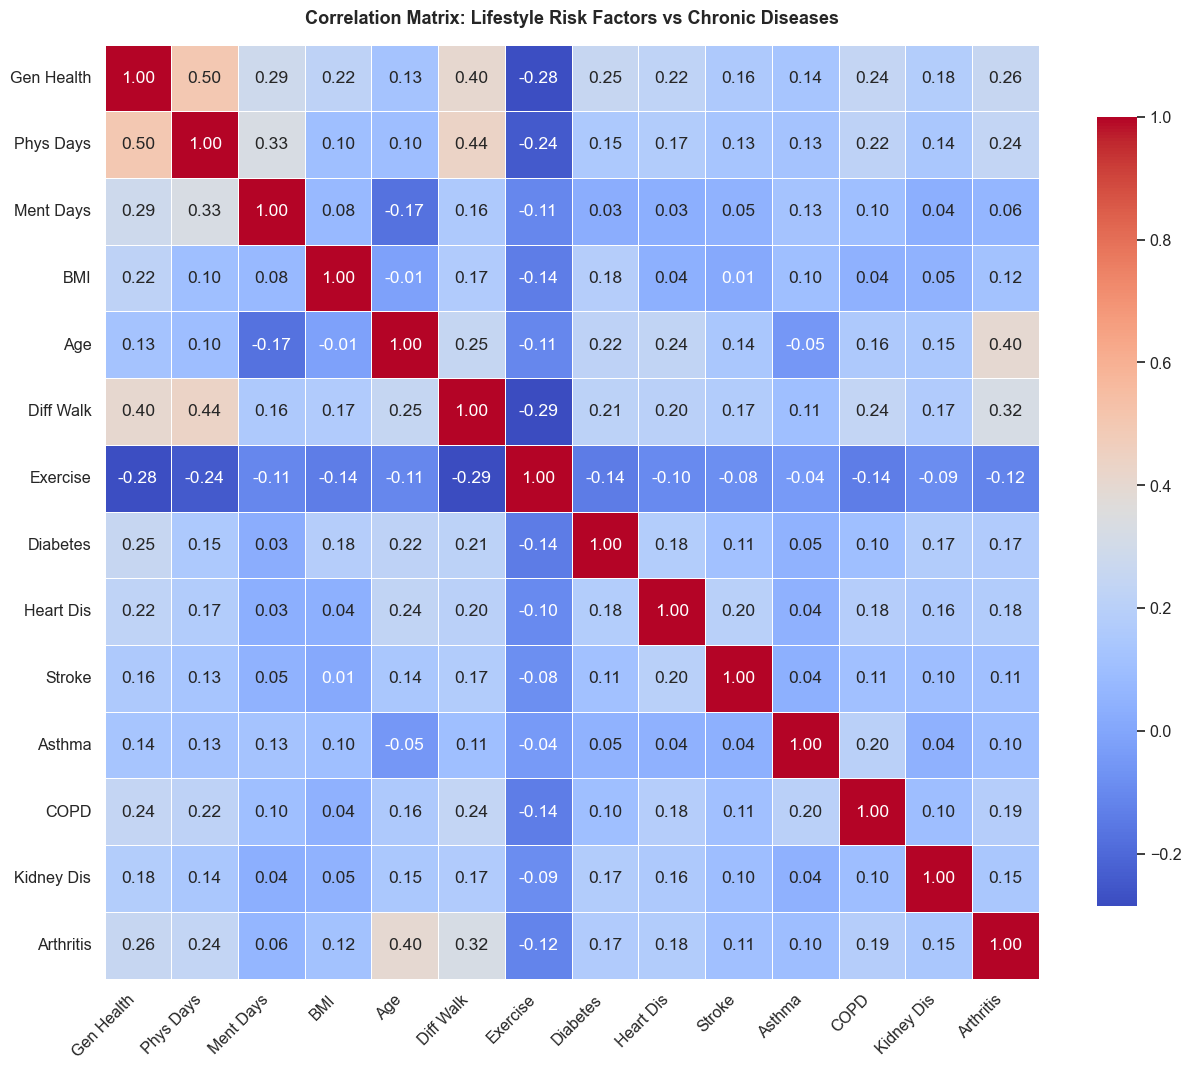

In [10]:
corr_cols = [
    'general_health', 'physical_health_days', 'mental_health_days',
    'bmi', 'age', 'diff_walk', 'exercise_any'
] + target_cols

corr_labels = [
    'Gen Health', 'Phys Days', 'Ment Days', 'BMI', 'Age', 'Diff Walk', 'Exercise',
    'Diabetes', 'Heart Dis', 'Stroke', 'Asthma', 'COPD', 'Kidney Dis', 'Arthritis'
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(13, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    xticklabels=corr_labels,
    yticklabels=corr_labels,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Matrix: Lifestyle Risk Factors vs Chronic Diseases', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


---
## 9. Key Observations and Implications for Modeling

1. **Prevalence Disparities and Class Imbalance:**
   - Arthritis (34.45%) and Asthma (15.63%) have relatively high positive representation.
   - Stroke (4.41%) and Kidney Disease (5.12%) exhibit severe class imbalance. Models predicting these diseases must incorporate balanced class weighting to ensure clinically meaningful sensitivity.
2. **Prominent Risk Predictors:**
   - **Age:** Shows strong positive correlation with Arthritis (r ≈ 0.36), Heart Disease (r ≈ 0.22), and Diabetes (r ≈ 0.20).
   - **General Health & Physical Health Days:** Correlate consistently across all conditions, reflecting generalized chronic health burden.
   - **Difficulty Walking:** Strongly associated with Arthritis, COPD, Heart Disease, and Stroke.
3. **Data Leakage Safeguards:**
   - To build a genuine multi-disease risk prediction system, all 7 target outcomes must be strictly excluded from the predictor feature pool for every individual model.
